# Progress 2 Proyek Data Science
##### PREDIKSI HARGA RUMAH DI WILAYAH YOGYAKARTA MELALUI PEMODELAN REGRESI BERBASIS DATA LISTING PROPERTI DARING

|No	|Aspek|			Item Penilaian |		
| --- | --- | --- | 
|1	|Data Understanding|			Sumber data & lisensi/izin			|
|2	|Data Understanding|			Data dictionary (variabel, tipe, unit)|			
|3	|Data Understanding|			Kualitas data (missing, outlier, duplikasi)|			
|4	|Data Understanding|			EDA berinsight (distribusi/korelasi)|			
|5	|Data Understanding|			Representativitas & bias sampel		|	
|6	|EDA|			Statistik deskriptif ditampilkan dan disimpulkan	|		
|7	|EDA		|	Visualisisasi fitur dan target, beri penjelasan atas temuan yang ada			|
|8	|	EDA|		Analisis korelasi antar fitur dan target. Cari minimal 3 insight yang dapat digunakan untuk keputusan cleaning atau modeling		|	
|9	|Audit kualitas data|			Menghitung dan analisis missing value, outlier, dan duplikat tiap kolom.			|
|10	|Cleaning|			Menyelesaikan masalah kualitas data dengan strategi yang tepat (misal median impute, drop data, atau mean impute)|			
|11	|	Cleaning		|Menampilkan kondisi sebelum vs sesudah dibersihkan|			
|12	|Preprocessing|			Menggunakan metode encoding, scaling, dan penanganan data imbalance yang tepat dan diberi alasan			|
|13	|	Preprocessing		|Melakukan spliting dataset antara train/test	|		
|14	|Feature Selection|			Memilih fitur yang sesuai disertai alasan dan diberi bukti. Jelaskan kenapa fitur dibuang dan dipakai, atau jike membuat fitur baru jelaskan mengapa fitur tersebut dibuat			|

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re as re

In [88]:
df = pd.read_csv("rumah123_yogya_unfiltered.csv")

### 1. Sumber Data dan Izin Penggunaan

| Aspek | Keterangan |
|---|---|
| Sumber asli | Listing properti pada portal Rumah123 (rumah123.com) yang di scraping menggunakan extension Chrome dengan nama Instant Data Scraper dengan kategori rumah dijual di wilayah Yogyakarta |
| Cara perolehan | Dataset publik di Kaggle: "Yogyakarta Housing Price (Indonesia)" (pramudya dika), berkas `rumah123_yogya_unfiltered.csv` |
| Periode pengambilan | 20 Maret – 21 Mei 2024 |
| Jumlah data mentah | 2.020 listing, 9 kolom |
| Lisensi dataset | Attribution-NonCommercial 4.0 International |
| Izin / ketentuan penggunaan | Dataset ini dilisensikan di bawah CC BY-NC. Penulis bebas menyebarkan dan memodifikasi data ini untuk tujuan non-komersial dengan wajib mencantumkan sumber asli." |

### 2. Data Dictionary

| Variabel | Tipe | Unit | Deskripsi | Nama setelah diolah |
|---|---|---|---|---|
| price | teks | Rupiah | Harga penawaran, mis. "Rp 1,79 Miliar" | `harga` (angka) |
| nav-link | teks | – | URL halaman listing | `listing_id` |
| description | teks | – | Judul/deskripsi iklan | `deskripsi` |
| listing-location | teks | – | Lokasi "area, kabupaten/kota" menurut portal | `area`, `kab_label` |
| bed | angka | jumlah | Jumlah kamar tidur | `kamar_tidur` |
| bath | angka | jumlah | Jumlah kamar mandi | `kamar_mandi` |
| carport | angka | jumlah | Jumlah carport | `carport` |
| surface_area | teks | m² | Luas tanah, mis. "120 m²" | `luas_tanah` (angka) |
| building_area | teks | m² | Luas bangunan, mis. "90 m²" | `luas_bangunan` (angka) |

**Variabel target:** `harga`. **Calon fitur:** lokasi, luas tanah, luas bangunan, kamar tidur, kamar mandi, carport.
Tabel ini diperbarui setelah proses cleaning.

In [89]:
# Data Mentah (df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   price             2020 non-null   str    
 1   nav-link          2020 non-null   str    
 2   description       2020 non-null   str    
 3   listing-location  2020 non-null   str    
 4   bed               2001 non-null   float64
 5   bath              1999 non-null   float64
 6   carport           1713 non-null   float64
 7   surface_area      2019 non-null   str    
 8   building_area     2019 non-null   str    
dtypes: float64(3), str(6)
memory usage: 142.2 KB


### 3. Audit Kualitas Data

Ada tiga hal yang diperiksa pada setiap kolom:
1. **Missing value**: sel yang kosong.
2. **Duplikat**: listing yang sama tercatat lebih dari sekali.
3. **Outlier**: nilai yang jauh di luar kebanyakan data, dideteksi dengan metode IQR.

In [90]:
# Harga: "Rp 1,79 Miliar" -> 1790000000
def ubah_harga(teks):
    teks = teks.lower().replace("rp", "").strip()
    bagian = teks.split()
    angka = bagian[0].replace(".", "").replace(",", ".")   # titik = ribuan, koma = desimal
    satuan = bagian[1] if len(bagian) > 1 else ""
    pengali = {"miliar": 1e9, "juta": 1e6, "ribu": 1e3}.get(satuan, 1)
    return float(angka) * pengali

# Luas: "120 m²" -> 120
def ubah_luas(kolom):
    teks = (kolom.str.replace(r"[^\d,\.]", "", regex=True)
                 .str.replace(".", "", regex=False)
                 .str.replace(",", ".", regex=False))
    return pd.to_numeric(teks, errors="coerce")

# Tabel baru yang lebih rapi
df_olah = pd.DataFrame()
df_olah["listing_id"]    = df["nav-link"].str.extract(r"(hos\d+)")[0]
df_olah["deskripsi"]     = df["description"].str.replace(r"\s+", " ", regex=True).str.strip()
df_olah["lokasi"]        = df["listing-location"].str.replace(r"\s+", " ", regex=True).str.strip()
df_olah["harga"]         = df["price"].apply(ubah_harga)
df_olah["luas_tanah"]    = ubah_luas(df["surface_area"])
df_olah["luas_bangunan"] = ubah_luas(df["building_area"])
df_olah["kamar_tidur"]   = df["bed"]
df_olah["kamar_mandi"]   = df["bath"]
df_olah["carport"]       = df["carport"]

df_sebelum = df_olah.copy()   # simpan kondisi SEBELUM cleaning untuk perbandingan nanti
df_olah.head()

,listing_id,deskripsi,lokasi,harga,luas_tanah,luas_bangunan,kamar_tidur,kamar_mandi,carport
0,hos17166670,Rumah 2 Lantai Baru di jalan Palagan Sleman Yo...,"Ngaglik, Sleman",1.790000e+09,120.0,110.0,3.0,3.0,2.0
1,hos17166674,RUMAH BARU DEKAT AL AZHAR DAN UGM,"Jombor, Sleman",1.700000e+08,102.0,126.0,3.0,2.0,1.0
2,hos17166621,RUMAH ASRI DAN SEJUK DI BERBAH SLEMAN DEKAT PA...,"Berbah, Sleman",6.950000e+08,100.0,100.0,2.0,2.0,1.0
3,hos17166607,Rumah Murah 5 Menit Dari Candi Prambanan Tersi...,"Prambanan, Sleman",5.600000e+08,109.0,67.0,3.0,1.0,1.0
4,hos17166601,Rumah Murah Cicilan 1jt Di Moyudan Sleman,"Moyudan, Sleman",2.000000e+08,60.0,30.0,2.0,1.0,1.0


In [91]:
missing = df_olah.isnull().sum()
pd.DataFrame({"missing": missing, "persen": (missing / len(df_olah) * 100).round(1)})

,missing,persen
listing_id,0,0.0
deskripsi,0,0.0
lokasi,0,0.0
harga,0,0.0
luas_tanah,1,0.0
luas_bangunan,1,0.0
kamar_tidur,19,0.9
kamar_mandi,21,1.0
carport,307,15.2


In [92]:
# duplicated() menghitung kemunculan kedua dan seterusnya (kopian)
kolom_spek = ["harga", "lokasi", "kamar_tidur", "kamar_mandi",
              "carport", "luas_tanah", "luas_bangunan"]

print("ID listing kembar        :", df_olah["listing_id"].duplicated().sum())
print("Deskripsi kembar (kopian):", df_olah["deskripsi"].duplicated().sum())
print("Spesifikasi kembar       :", df_olah.duplicated(kolom_spek).sum())

ID listing kembar        : 0
Deskripsi kembar (kopian): 98
Spesifikasi kembar       : 438


In [93]:
def hitung_outlier(kolom):
    q1, q3 = kolom.quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((kolom < bawah) | (kolom > atas)).sum()

angka = ["harga", "luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]
outlier = pd.Series({k: hitung_outlier(df_olah[k]) for k in angka})
outlier["log10(harga)"] = hitung_outlier(np.log10(df_olah["harga"]))

pd.DataFrame({"outlier": outlier,
              "persen": (outlier / len(df_olah) * 100).round(1)})

,outlier,persen
harga,155,7.7
luas_tanah,240,11.9
luas_bangunan,167,8.3
kamar_tidur,145,7.2
kamar_mandi,115,5.7
carport,88,4.4
log10(harga),21,1.0


### Temuan Audit

| Aspek | Temuan | Rencana |
|---|---|---|
| Missing `carport` | 307 baris (15,2%) | Diisi 0 dan diberi penanda `carport_kosong` (alasan di Tahap 5) |
| Missing kamar tidur / kamar mandi | 19 / 21 baris (≈1%) | Diisi median |
| Missing luas tanah / bangunan | 1 baris tiap kolom | Baris dibuang |
| Duplikat ID listing | 0 | Tidak ada tindakan |
| Duplikat deskripsi | 98 kopian | Belum tentu duplikat (bisa teks template), dicek dengan spesifikasi |
| Duplikat spesifikasi | 438 | Dibuang, karena itu listing yang sama |
| Outlier IQR | harga 155, luas tanah 240, luas bangunan 167, kamar tidur 145, kamar mandi 115, carport 88 | IQR hanya penanda, bukan dasar membuang |
| Outlier harga setelah log | turun ke 21 | Target dipakai dalam bentuk log |

### 4. Cleaning Data

Strategi untuk tiap masalah:

| Masalah | Strategi | Alasan |
|---|---|---|
| Duplikat spesifikasi | Dibuang | Spesifikasi sama persis berarti listing yang sama |
| Harga < Rp 50 juta atau > Rp 20 miliar | Dibuang | Tidak wajar untuk rumah di Yogyakarta |
| Kamar tidur atau kamar mandi > 10 | Dibuang | Kemungkinan bukan rumah tinggal (kos, penginapan) |
| Luas tanah atau bangunan ≤ 15 m², luas bangunan > 5.000 m² | Dibuang | Tidak masuk akal |
| Luas bangunan > 3× luas tanah | Dibuang | Kemungkinan salah input |
| Bukan hunian (kos, ruko, gudang, tanah kosong, dll.) | Dibuang | Di luar cakupan prediksi harga rumah |
| Luas tanah/bangunan kosong | Baris dibuang | Hanya 1 baris dan fitur terpenting |
| Carport kosong | Diisi 0 + kolom penanda `carport_kosong` | Kosong belum tentu "tidak punya": rumah dengan carport kosong bermedian harga Rp 1,6 miliar, lebih tinggi dari rumah ber-carport 1 (Rp 780 juta), sehingga penanda membiarkan model membedakannya |
| Kamar tidur/mandi kosong | Diisi median di Tahap 7 | Dipelajari dari data train agar tidak bocor ke data uji |

Luas bangunan > luas tanah **tidak** dibuang karena rumah bertingkat memang wajar.
Outlier IQR **tidak** dipakai untuk membuang data, hanya sebagai penanda.

In [94]:
d = df_olah["deskripsi"].str.lower()

aturan = pd.DataFrame({
    "duplikat spesifikasi"      : df_olah.duplicated(kolom_spek),
    "harga tidak wajar"         : (df_olah["harga"] < 5e7) | (df_olah["harga"] > 2e10),
    "kamar tidur > 10"          : df_olah["kamar_tidur"] > 10,
    "kamar mandi > 10"          : df_olah["kamar_mandi"] > 10,
    "luas <= 15 m2"             : (df_olah["luas_tanah"] <= 15) | (df_olah["luas_bangunan"] <= 15),
    "luas bangunan > 5000 m2"   : df_olah["luas_bangunan"] > 5000,
    "luas bangunan > 3x tanah"  : df_olah["luas_bangunan"] > 3 * df_olah["luas_tanah"],
    "bukan hunian"              : (d.str.contains(r"^\s*(?:dijual\s+|jual\s+)?(?:tanah|kavling|kapling|hotel|villa|vila|kos)\b")
                                   | d.str.contains(r"\b(?:kost|ruko|gudang|pabrik|homestay)\b")
                                   | (d.str.contains("tanah") & ~d.str.contains("rumah|rmh"))),
})

print("Baris terkena tiap aturan:")
print(aturan.sum().to_string())
print("\nTotal baris yang dibuang:", aturan.any(axis=1).sum())

Baris terkena tiap aturan:
duplikat spesifikasi        438
harga tidak wajar            11
kamar tidur > 10             91
kamar mandi > 10             71
luas <= 15 m2                 3
luas bangunan > 5000 m2       2
luas bangunan > 3x tanah      9
bukan hunian                158

Total baris yang dibuang: 628


In [95]:
df_clean = df_olah[~aturan.any(axis=1)].copy()          # buang baris bermasalah
df_clean = df_clean.dropna(subset=["luas_tanah", "luas_bangunan"])   # luas kosong
df_clean["carport_kosong"] = df_clean["carport"].isnull().astype(int)   # 1 = awalnya kosong
df_clean["carport"] = df_clean["carport"].fillna(0)

print("Sebelum cleaning:", len(df_sebelum), "baris")
print("Sesudah cleaning:", len(df_clean), "baris")

Sebelum cleaning: 2020 baris
Sesudah cleaning: 1391 baris


In [96]:
angka = ["harga", "luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]

pd.DataFrame({
    "missing_sebelum": df_sebelum[angka].isnull().sum(),
    "missing_sesudah": df_clean[angka].isnull().sum(),
    "median_sebelum" : df_sebelum[angka].median(),
    "median_sesudah" : df_clean[angka].median(),
    "max_sebelum"    : df_sebelum[angka].max(),
    "max_sesudah"    : df_clean[angka].max(),
})

,missing_sebelum,missing_sesudah,median_sebelum,median_sesudah,max_sebelum,max_sesudah
harga,0,0,1.100000e+09,990000000.0,4.210000e+10,1.600000e+10
luas_tanah,1,0,1.200000e+02,120.0,4.222000e+03,4.222000e+03
luas_bangunan,1,0,1.000000e+02,100.0,2.408150e+09,1.000000e+03
kamar_tidur,19,16,3.000000e+00,3.0,4.900000e+01,1.000000e+01
kamar_mandi,21,17,2.000000e+00,2.0,4.900000e+01,1.000000e+01
carport,307,0,1.000000e+00,1.0,1.500000e+01,1.500000e+01


### Hasil Cleaning

| Aturan | Baris terkena |
|---|---|
| Duplikat spesifikasi | 438 |
| Bukan hunian | 158 |
| Kamar tidur > 10 | 91 |
| Kamar mandi > 10 | 71 |
| Harga tidak wajar | 11 |
| Luas bangunan > 3× luas tanah | 9 |
| Luas ≤ 15 m² | 3 |
| Luas bangunan > 5.000 m² | 2 |
| **Total baris unik dibuang** | **628** (sebagian baris terkena lebih dari satu aturan) |
| Luas kosong | 1 |
| **Data bersih** | **1.391 baris** |

Perbandingan sebelum vs sesudah: luas bangunan maksimum 2,4 miliar m² → 1.000 m² (salah input terbuang), kamar maksimum 49 → 10, missing `carport` 307 → 0.

### 5. Eksplorasi Data (EDA)

In [97]:
# Area dan wilayah diambil dari data mentah (nomor barisnya sama dengan df_clean)
area = df["listing-location"].str.split(",").str[0].str.strip()
slug = df["nav-link"].str.extract(r"properti/([^/]+)/")[0]

nama = {"sleman": "Sleman", "bantul": "Bantul", "yogyakarta": "Kota Yogyakarta",
        "kulon-progo": "Kulon Progo", "gunung-kidul": "Gunung Kidul"}
wilayah = slug.map(nama)

# Kategori "yogyakarta" di portal ternyata memuat area di luar kota (Sleman, Bantul, Kulon Progo)
koreksi = {"Maguwoharjo": "Sleman", "Sleman": "Sleman", "Kaliurang": "Sleman", "Pogung": "Sleman",
           "Seturan": "Sleman", "Caturtunggal": "Sleman", "Cebongan": "Sleman",
           "Purwomartani": "Sleman", "Nologaten": "Sleman", "Sekip": "Sleman",
           "Bantul": "Bantul", "Imogiri": "Bantul", "Kulonprogo": "Kulon Progo"}
portal_yogya = slug.eq("yogyakarta")
wilayah[portal_yogya] = area[portal_yogya].map(koreksi).fillna("Kota Yogyakarta")

df_clean["area"]       = area
df_clean["wilayah"]    = wilayah
df_clean["harga_juta"] = df_clean["harga"] / 1e6
df_clean[["area", "wilayah"]].head()

,area,wilayah
0,Ngaglik,Sleman
1,Jombor,Sleman
2,Berbah,Sleman
3,Prambanan,Sleman
4,Moyudan,Sleman


In [98]:
df_clean[df_clean["carport"] > 5][["deskripsi", "harga_juta", "luas_tanah", "luas_bangunan", "carport"]]

,deskripsi,harga_juta,luas_tanah,luas_bangunan,carport
111,Rumah Jogja Dijual Dekat Alun alun Kidul,4250.0,425.0,150.0,6.0
120,Rumah di Jogja Dijual Dekat Hotel Tentrem Yogy...,4200.0,564.0,190.0,8.0
129,"Rumah Besar + Kolam renang Jakal km.7,5",8900.0,1050.0,735.0,8.0
182,Rumah Besar Condongcatur Timur Banteng,4500.0,503.0,300.0,7.0
366,"Rumah Mewah Kaliurang Yogakarta, 450 Meter Jog...",8000.0,1300.0,1000.0,6.0
441,Rumah Mewah Jogja Dekat Hotel Tentrem Mlati Sl...,4200.0,564.0,190.0,8.0
642,Cafe Dan Resto Strategis Selatan UII Dan Besi ...,1650.0,351.0,270.0,11.0
691,Rumah modern tanah luas dekat Ugm,4500.0,584.0,150.0,8.0
696,Rumah Guest House Di Jual Di Jogja Furnished 5...,2350.0,184.0,160.0,10.0
715,Rumah Siap Huni Secondary Dengan Halaman Luas ...,2750.0,579.0,150.0,8.0


In [99]:
# Temuan EDA: baris 642 adalah cafe & resto, lolos aturan "bukan hunian"
df_clean = df_clean.drop(index=642)
print("Data bersih sekarang:", len(df_clean), "baris")

Data bersih sekarang: 1390 baris


In [100]:
angka = ["harga_juta", "luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]

ringkas = df_clean[angka].describe().T
ringkas["skewness"] = df_clean[angka].skew()
display(ringkas.round(2))

print("Harga <= Rp 1 miliar:", round((df_clean["harga_juta"] <= 1000).mean() * 100, 1), "%")
print("Carport > 5         :", (df_clean["carport"] > 5).sum(), "baris")

,count,mean,std,min,25%,50%,75%,max,skewness
harga_juta,1390.0,1579.91,1634.67,69.0,645.0,990.0,1950.00,16000.0,3.42
luas_tanah,1390.0,168.81,200.73,36.0,96.0,120.0,164.75,4222.0,9.31
luas_bangunan,1390.0,128.86,110.48,23.0,60.0,100.0,156.00,1000.0,3.28
kamar_tidur,1374.0,3.24,1.23,1.0,2.0,3.0,4.00,10.0,1.54
kamar_mandi,1373.0,2.31,1.24,1.0,1.0,2.0,3.00,10.0,1.33
carport,1390.0,1.22,1.06,0.0,1.0,1.0,2.00,15.0,4.01


Harga <= Rp 1 miliar: 51.4 %
Carport > 5         : 14 baris


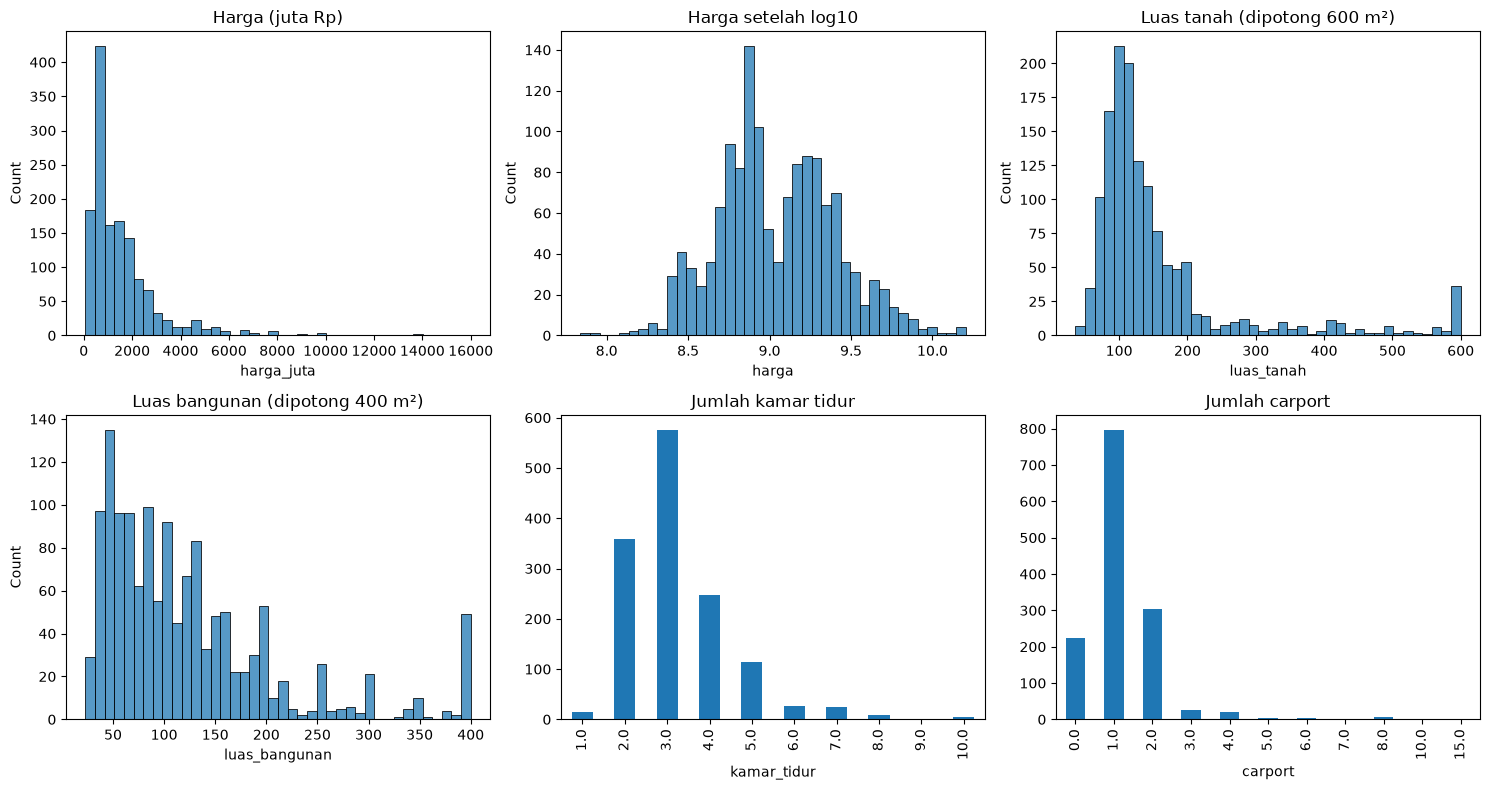

In [101]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

sns.histplot(df_clean["harga_juta"], bins=40, ax=ax[0, 0]);               ax[0, 0].set_title("Harga (juta Rp)")
sns.histplot(np.log10(df_clean["harga"]), bins=40, ax=ax[0, 1]);          ax[0, 1].set_title("Harga setelah log10")
sns.histplot(df_clean["luas_tanah"].clip(upper=600), bins=40, ax=ax[0, 2]);    ax[0, 2].set_title("Luas tanah (dipotong 600 m²)")
sns.histplot(df_clean["luas_bangunan"].clip(upper=400), bins=40, ax=ax[1, 0]); ax[1, 0].set_title("Luas bangunan (dipotong 400 m²)")
df_clean["kamar_tidur"].value_counts().sort_index().plot(kind="bar", ax=ax[1, 1]); ax[1, 1].set_title("Jumlah kamar tidur")
df_clean["carport"].value_counts().sort_index().plot(kind="bar", ax=ax[1, 2]);     ax[1, 2].set_title("Jumlah carport")

plt.tight_layout(); plt.show()

,listing,median_harga_juta,porsi_%
wilayah,,,
Sleman,1007,1250.0,72.4
Bantul,218,662.5,15.7
Kota Yogyakarta,132,1375.0,9.5
Kulon Progo,28,278.0,2.0
Gunung Kidul,5,310.0,0.4


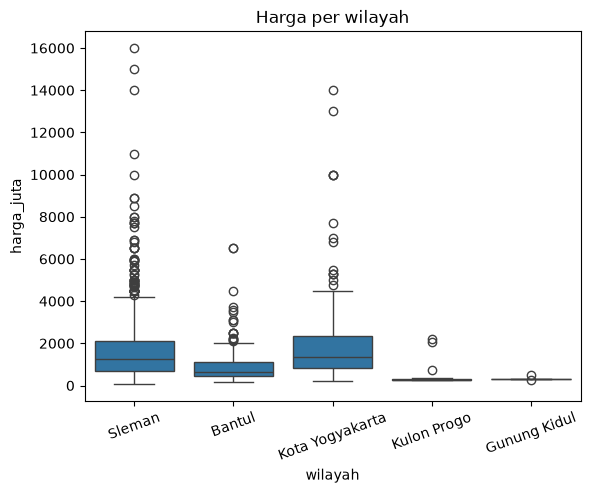

In [102]:
tabel = df_clean.groupby("wilayah").agg(listing=("harga", "size"),
                                        median_harga_juta=("harga_juta", "median"))
tabel["porsi_%"] = (tabel["listing"] / tabel["listing"].sum() * 100).round(1)
tabel = tabel.sort_values("listing", ascending=False)
display(tabel.round(1))

sns.boxplot(data=df_clean, x="wilayah", y="harga_juta", order=tabel.index)
plt.xticks(rotation=20); plt.title("Harga per wilayah"); plt.show()

### Kesimpulan Statistik dan Visualisasi

- **Harga:** distribusi miring ke kanan (skewness 3,42). Median Rp 990 juta, rata-rata Rp 1,58 miliar, dan 51,4% rumah berharga ≤ Rp 1 miliar. Setelah log10 bentuknya lebih simetris, sehingga `log(harga)` cocok dipakai sebagai target.
- **Luas tanah:** paling miring (skewness 9,30). Median 120 m², tetapi ada tanah sampai 4.222 m². Fitur ini perlu dipertimbangkan untuk ditransformasi log.
- **Luas bangunan:** median 100 m², skewness 3,28.
- **Kamar dan carport:** kebanyakan rumah punya 3 kamar tidur (median), 2 kamar mandi, dan 1 carport. Hanya 15 rumah dengan carport > 5.
- **Wilayah:** median harga tertinggi di Kota Yogyakarta (Rp 1,375 miliar) dan Sleman (Rp 1,25 miliar), lalu Bantul (Rp 662 juta). Kulon Progo dan Gunung Kidul paling murah.

### Representativitas dan Bias Sampel

| Sumber bias | Penjelasan |
|---|---|
| Dominasi wilayah | 72,5% data dari Sleman; Kota Yogyakarta hanya 9,5%. Kulon Progo (28 listing) dan Gunung Kidul (5 listing) terlalu sedikit sehingga median harganya tidak andal dan prediksi di sana kurang akurat |
| Harga tawar | Data berisi harga penawaran di iklan, bukan harga transaksi |
| Satu portal | Hanya listing Rumah123; rumah yang dijual tanpa iklan daring tidak terwakili |
| Waktu | Data hanya potret satu periode pengambilan, tidak menangkap tren harga |

### 6. Analisis Korelasi

Korelasi menunjukkan seberapa kuat dua variabel bergerak bersama (−1 sampai 1). Dipakai **Spearman** karena data miring dan banyak nilai ekstrem.

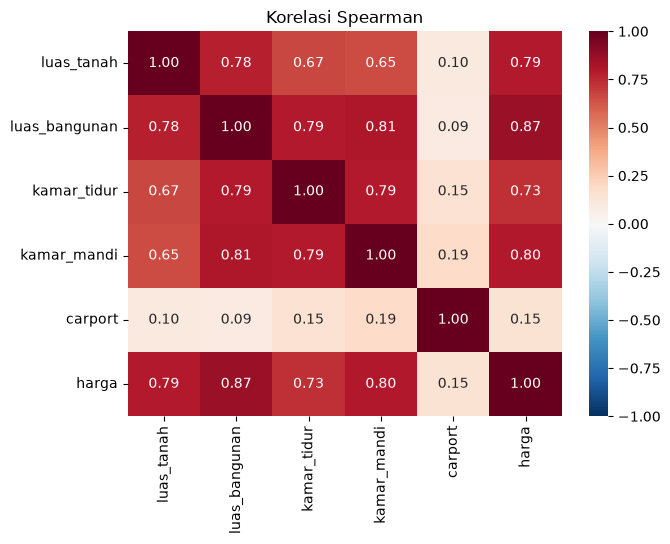

Korelasi Spearman dengan harga:
luas_bangunan    0.87
kamar_mandi      0.80
luas_tanah       0.79
kamar_tidur      0.73
carport          0.15
Name: harga, dtype: float64


In [103]:
df_clean["harga_log"] = np.log10(df_clean["harga"])
fitur = ["luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]

kor = df_clean[fitur + ["harga"]].corr(method="spearman")
plt.figure(figsize=(7, 5))
sns.heatmap(kor, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Korelasi Spearman"); plt.show()

print("Korelasi Spearman dengan harga:")
print(kor["harga"].drop("harga").sort_values(ascending=False).round(2))

In [104]:
pd.DataFrame({
    "pearson_harga"    : df_clean[fitur + ["harga"]].corr()["harga"].drop("harga"),
    "pearson_log_harga": df_clean[fitur + ["harga_log"]].corr()["harga_log"].drop("harga_log"),
}).round(2)

,pearson_harga,pearson_log_harga
luas_tanah,0.58,0.50
luas_bangunan,0.78,0.73
kamar_tidur,0.56,0.66
kamar_mandi,0.60,0.73
carport,0.26,0.24


In [105]:
log_luas = np.log10(df_clean[["luas_tanah", "luas_bangunan"]])
print("Pearson log(luas) vs log(harga):")
print(log_luas.corrwith(df_clean["harga_log"]).round(2))

Pearson log(luas) vs log(harga):
luas_tanah       0.76
luas_bangunan    0.86
dtype: float64


In [106]:
df_clean.groupby("carport_kosong")["harga_juta"].agg(["size", "median"])

,size,median
carport_kosong,,
0,1166,900.0
1,224,1600.0


### Insight untuk Cleaning dan Modeling

1. **Ukuran rumah penentu harga terkuat.** Korelasi Spearman dengan harga: luas bangunan 0,87, kamar mandi 0,80, luas tanah 0,79, kamar tidur 0,73. Semuanya dipakai sebagai fitur.
2. **Transformasi log pada target dan luas.** Log harga menurunkan outlier harga dari 155 menjadi 21. Korelasi Pearson luas dengan harga hanya 0,58 (tanah) dan 0,78 (bangunan), tetapi setelah **kedua sisi** di-log naik menjadi 0,76 dan 0,86. Keputusan: target `log(harga)` dan `log(luas_tanah)`, `log(luas_bangunan)` sebagai fitur.
3. **Wilayah berpengaruh.** Median harga Kota Yogyakarta (Rp 1,375 miliar) dan Sleman (Rp 1,25 miliar) sekitar 2× Bantul (Rp 662 juta), sehingga `wilayah` di-encode sebagai fitur (Tahap 8).
4. **Carport kosong bukan "tidak punya".** Korelasi carport lemah (0,15). Dari 224 rumah dengan carport kosong, median harganya Rp 1,6 miliar, lebih tinggi daripada rumah ber-carport 1 (Rp 780 juta). Tidak ada nilai 0 asli di data. Keputusan: kosong diisi 0 dan ditambah penanda `carport_kosong`. Nilai 0 pada `carport` setelah diproses berarti "tidak dicantumkan", bukan "tidak punya".
5. **Fitur ukuran saling berkaitan.** [ISI: pasangan fitur dengan korelasi > 0,8 dari heatmap]. Diperiksa dengan VIF di Tahap 9.

### 7. Pembagian Data Latih dan Uji

Data dibagi **80% latih (train)** dan **20% uji (test)**. Pembagian dilakukan **sebelum** imputasi, encoding, dan scaling, supaya statistik data uji tidak "bocor" ke proses belajar. Pembagian distratifikasi per `wilayah` agar proporsi wilayah di train dan test sama.

In [108]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df_clean, test_size=0.2, random_state=42,
                               stratify=df_clean["wilayah"])
print("Train:", len(train), "baris | Test:", len(test), "baris")

pd.DataFrame({"train_%": train["wilayah"].value_counts(normalize=True) * 100,
              "test_%" : test["wilayah"].value_counts(normalize=True) * 100}).round(1)

Train: 1112 baris | Test: 278 baris


,train_%,test_%
wilayah,,
Sleman,72.5,72.3
Bantul,15.6,15.8
Kota Yogyakarta,9.5,9.4
Kulon Progo,2.0,2.2
Gunung Kidul,0.4,0.4


Keterbatasan: beberapa listing hampir identik (deskripsi sama, spesifikasi mirip) dan bisa jatuh ke train dan test sekaligus, sehingga skor uji bisa sedikit lebih optimistis daripada kenyataan.

### 8. Penanganan Missing Value yang Tersisa

`kamar_tidur` dan `kamar_mandi` masih punya sedikit nilai kosong (≈1%). Strategi: **imputasi median**, karena kedua kolom berupa hitungan kamar yang miring ke kanan sehingga median lebih tahan terhadap nilai besar daripada rata-rata. Median dihitung dari **data train saja**, lalu dipakai juga untuk mengisi data test.

In [109]:
train = train.copy()
test  = test.copy()

kolom = ["kamar_tidur", "kamar_mandi"]
print("Missing SEBELUM imputasi:")
print(pd.DataFrame({"train": train[kolom].isnull().sum(), "test": test[kolom].isnull().sum()}))

for k in kolom:
    median_train = train[k].median()      # dihitung dari train saja
    print(f"Median {k} (train): {median_train}")
    train[k] = train[k].fillna(median_train)
    test[k]  = test[k].fillna(median_train)

print("\nMissing SESUDAH imputasi:")
print(pd.DataFrame({"train": train[kolom].isnull().sum(), "test": test[kolom].isnull().sum()}))

Missing SEBELUM imputasi:
             train  test
kamar_tidur      9     7
kamar_mandi     10     7
Median kamar_tidur (train): 3.0
Median kamar_mandi (train): 2.0

Missing SESUDAH imputasi:
             train  test
kamar_tidur      0     0
kamar_mandi      0     0


### 9. Encoding, Scaling, dan Imbalance

| Langkah | Metode | Alasan |
|---|---|---|
| Target | `log10(harga)` | Harga miring ke kanan (skewness 3,42). Setelah log bentuknya lebih simetris dan outlier turun dari 155 menjadi 21. Hasil prediksi dikembalikan ke Rupiah dengan `10 ** prediksi` |
| Luas tanah dan bangunan | `log10` | Luas juga miring. Setelah log, korelasi dengan harga naik dari 0,58 ke 0,76 (tanah) dan 0,78 ke 0,86 (bangunan) |
| `wilayah` | One-hot encoding | Wilayah adalah kategori tanpa urutan. Label 0, 1, 2, … akan memberi kesan urutan palsu |
| `area` | Tidak dipakai | Ada 57 area untuk hanya 1.112 baris train (akan menambah 56 kolom), dan 24 area punya < 5 listing sehingga estimasinya tidak stabil. Lokasi tetap diwakili oleh `wilayah` |
| Scaling | `StandardScaler`, dipelajari dari train | Model linear, KNN, dan SVR sensitif pada skala. Hanya kolom numerik kontinu yang di-scale, bukan kolom 0/1 |
| Imbalance | Tidak diterapkan | Target berupa angka (regresi). SMOTE atau class weight hanya untuk klasifikasi. Ketimpangan wilayah (Sleman 72,5%) ditangani dengan stratified split |

In [ ]:
# bukti kenapa area tidak dipakai
jumlah = train["area"].value_counts()
print("Jumlah area unik          :", len(jumlah))
print("Area dengan < 5 listing   :", (jumlah < 5).sum())
print("Listing di area langka    :", jumlah[jumlah < 5].sum(), "dari", len(train))

Jumlah area unik          : 57
Area dengan < 5 listing   : 24
Listing di area langka    : 55 dari 1112


In [112]:
# menyiapkan target dan fitur
def siapkan(d):
    x = pd.DataFrame(index=d.index)
    x["log_luas_tanah"]    = np.log10(d["luas_tanah"])
    x["log_luas_bangunan"] = np.log10(d["luas_bangunan"])
    x["kamar_tidur"]       = d["kamar_tidur"]
    x["kamar_mandi"]       = d["kamar_mandi"]
    x["carport"]           = d["carport"]
    x["carport_kosong"]    = d["carport_kosong"]
    x["wilayah"]           = d["wilayah"]
    return x

X_train, X_test = siapkan(train), siapkan(test)
y_train = np.log10(train["harga"])
y_test  = np.log10(test["harga"])
X_train.head()

,log_luas_tanah,log_luas_bangunan,kamar_tidur,kamar_mandi,carport,carport_kosong,wilayah
169,1.924279,1.698970,2.0,1.0,1.0,0,Sleman
232,2.146128,2.198657,3.0,2.0,1.0,0,Sleman
896,2.071882,2.204120,4.0,3.0,1.0,0,Bantul
1676,2.346353,2.447158,4.0,5.0,2.0,0,Sleman
294,2.250420,2.117271,4.0,4.0,2.0,0,Sleman


In [113]:
# one-hot encoding
# drop_first=True: satu wilayah (Bantul) jadi pembanding, tidak perlu kolom sendiri
X_train = pd.get_dummies(X_train, columns=["wilayah"], drop_first=True, dtype=int)

# test mengikuti kolom train, kolom yang tidak ada diisi 0
X_test = pd.get_dummies(X_test, columns=["wilayah"], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Kolom fitur:", list(X_train.columns))

Kolom fitur: ['log_luas_tanah', 'log_luas_bangunan', 'kamar_tidur', 'kamar_mandi', 'carport', 'carport_kosong', 'wilayah_Gunung Kidul', 'wilayah_Kota Yogyakarta', 'wilayah_Kulon Progo', 'wilayah_Sleman']


In [114]:
# scalling
from sklearn.preprocessing import StandardScaler

angka = ["log_luas_tanah", "log_luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]

print("Sebelum scaling (train):")
print(X_train[angka].describe().loc[["mean", "std"]].round(2))

scaler = StandardScaler()
X_train[angka] = scaler.fit_transform(X_train[angka])   # belajar dari train
X_test[angka]  = scaler.transform(X_test[angka])        # test hanya ikut

print("\nSesudah scaling (train):")
print(X_train[angka].describe().loc[["mean", "std"]].round(2))

Sebelum scaling (train):
      log_luas_tanah  log_luas_bangunan  kamar_tidur  kamar_mandi  carport
mean            2.13               2.01         3.26         2.31     1.23
std             0.25               0.29         1.25         1.25     1.11

Sesudah scaling (train):
      log_luas_tanah  log_luas_bangunan  kamar_tidur  kamar_mandi  carport
mean            -0.0               -0.0          0.0          0.0      0.0
std              1.0                1.0          1.0          1.0      1.0


### 10. Pemilihan Fitur

Dua bukti yang dipakai:
1. **VIF** mengukur apakah sebuah fitur bisa ditebak dari fitur lain. VIF < 5 aman, > 10 berarti fitur kembar yang perlu dipilih salah satu.
2. **Uji buang-satu-fitur** (5-fold cross-validation pada data train, model regresi linear sederhana). Kenaikan error (RMSE dalam log10 harga) saat sebuah fitur dibuang menunjukkan seberapa berguna fitur itu. Kenaikan mendekati 0 berarti fitur boleh dibuang.

In [115]:
# metode vif
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

Xv = add_constant(X_train.astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=X_train.columns)
vif.sort_values(ascending=False).round(2)

log_luas_bangunan          4.04
kamar_mandi                3.12
kamar_tidur                2.97
log_luas_tanah             2.79
carport                    1.68
wilayah_Sleman             1.64
carport_kosong             1.58
wilayah_Kota Yogyakarta    1.53
wilayah_Kulon Progo        1.14
wilayah_Gunung Kidul       1.03
dtype: float64

In [116]:
# uji buang-satu-fitur
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

def rmse_cv(kolom):
    skor = cross_val_score(LinearRegression(), X_train[kolom], y_train,
                           cv=5, scoring="neg_root_mean_squared_error")
    return -skor.mean()

grup = {
    "luas tanah"    : ["log_luas_tanah"],
    "luas bangunan" : ["log_luas_bangunan"],
    "kamar tidur"   : ["kamar_tidur"],
    "kamar mandi"   : ["kamar_mandi"],
    "carport"       : ["carport"],
    "carport_kosong": ["carport_kosong"],
    "wilayah"       : [c for c in X_train.columns if c.startswith("wilayah_")],
}

semua = list(X_train.columns)
dasar = rmse_cv(semua)
print("RMSE dengan semua fitur:", round(dasar, 4), "(satuan log10 harga)")

hasil = {nama: rmse_cv([c for c in semua if c not in kolom]) - dasar
         for nama, kolom in grup.items()}
pd.Series(hasil, name="kenaikan_RMSE_jika_dibuang").sort_values(ascending=False).round(4)

RMSE dengan semua fitur: 0.1705 (satuan log10 harga)


luas bangunan     0.0278
luas tanah        0.0074
kamar mandi       0.0040
wilayah           0.0020
kamar tidur       0.0005
carport_kosong   -0.0005
carport          -0.0005
Name: kenaikan_RMSE_jika_dibuang, dtype: float64

In [117]:
uji = {
    "tanpa carport & carport_kosong"            : ["carport", "carport_kosong"],
    "tanpa kamar_tidur"                         : ["kamar_tidur"],
    "tanpa kamar_tidur, carport, carport_kosong": ["kamar_tidur", "carport", "carport_kosong"],
}
for nama, buang in uji.items():
    r = rmse_cv([c for c in semua if c not in buang])
    print(f"{nama:45s} RMSE = {r:.4f}  (selisih {r - dasar:+.4f})")

tanpa carport & carport_kosong                RMSE = 0.1700  (selisih -0.0006)
tanpa kamar_tidur                             RMSE = 0.1711  (selisih +0.0005)
tanpa kamar_tidur, carport, carport_kosong    RMSE = 0.1708  (selisih +0.0002)


### Keputusan Fitur

**Bukti:** VIF tertinggi 4,04 (`log_luas_bangunan`), semua < 5, sehingga tidak ada fitur yang dibuang karena multikolinearitas. Pada uji buang-satu-fitur (5-fold CV, regresi linear, RMSE semua fitur 0,1705 log10 harga), kenaikan RMSE tertinggi pada luas bangunan (0,0278).

**Fitur dipakai**

| Fitur | Alasan dan bukti |
|---|---|
| `log_luas_bangunan` | Korelasi tertinggi (Spearman 0,87; Pearson log-log 0,86). Dibuang: RMSE naik 0,0278 |
| `log_luas_tanah` | Korelasi 0,79 (Spearman), 0,76 (Pearson log-log). Dibuang: RMSE naik 0,0074 |
| `kamar_mandi` | Korelasi 0,80. Dibuang: RMSE naik 0,0040 |
| `wilayah` (one-hot) | Median harga Kota Yogyakarta dan Sleman sekitar 2× Bantul. Dibuang: RMSE naik 0,0020 |

**Fitur dibuang**

| Fitur | Alasan dan bukti |
|---|---|
| `kamar_tidur` | Korelasi tinggi dengan harga (0,73) tetapi tumpang tindih dengan luas bangunan dan kamar mandi. Dibuang: RMSE hanya naik 0,0005 |
| `carport`, `carport_kosong` | Korelasi lemah (0,15). Dibuang bersamaan: RMSE turun 0,0006. `carport_kosong` adalah fitur baru (penanda carport yang tidak dicantumkan) yang dibuat karena kosong ≠ tidak punya; ternyata harga tinggi pada kelompok ini dijelaskan oleh ukuran rumah [ISI: dari cek luas_bangunan] |
| `area` | 57 kategori untuk 1.112 baris train dan 24 di antaranya < 5 listing |
| `harga_juta`, `harga_log` | Turunan dari target (kebocoran target) |
| `listing_id` | Hanya identitas, tidak berhubungan dengan harga |
| `deskripsi`, `lokasi` | Teks bebas, hanya dipakai untuk mendeteksi properti non-hunian dan duplikat |

**Keterbatasan:** pengujian memakai regresi linear. Model berbasis pohon bisa memanfaatkan `kamar_tidur` atau `carport` secara berbeda, sehingga keputusan ini diuji ulang saat pemodelan.

In [118]:
fitur_final = ["log_luas_bangunan", "log_luas_tanah", "kamar_mandi"] + \
              [c for c in X_train.columns if c.startswith("wilayah_")]

X_train_final = X_train[fitur_final]
X_test_final  = X_test[fitur_final]
print("Fitur final:", fitur_final)
print("Bentuk data:", X_train_final.shape, X_test_final.shape)

Fitur final: ['log_luas_bangunan', 'log_luas_tanah', 'kamar_mandi', 'wilayah_Gunung Kidul', 'wilayah_Kota Yogyakarta', 'wilayah_Kulon Progo', 'wilayah_Sleman']
Bentuk data: (1112, 7) (278, 7)
